In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from imblearn.over_sampling import SMOTE

In [3]:
filepath = "/content/drive/MyDrive/Colab Notebooks/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(filepath)

In [4]:
df.shape

(7043, 21)

In [5]:
df.size

147903

In [6]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
missing = df.isna().sum()
print(missing) #checking missing values

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


##Checkind duplicates

In [11]:
df.duplicated().sum() #checking duplicates

np.int64(0)

#EDA

In [12]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [13]:
for col in df.columns:
    print(col, ":", df[col].unique())

customerID : ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender : ['Female' 'Male']
SeniorCitizen : [0 1]
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
tenure : [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank tr

##visualization

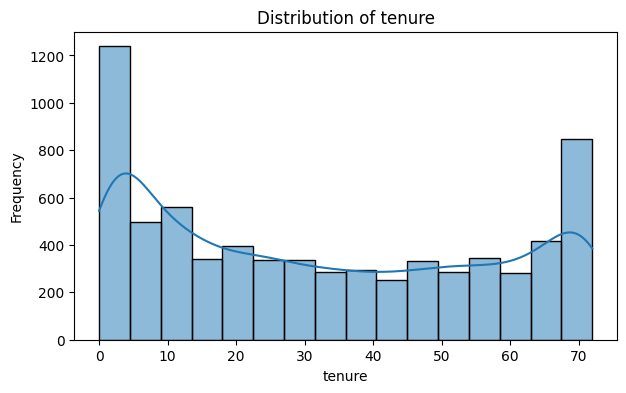

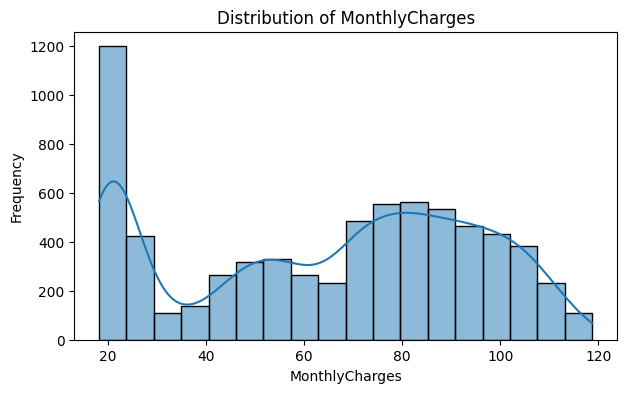

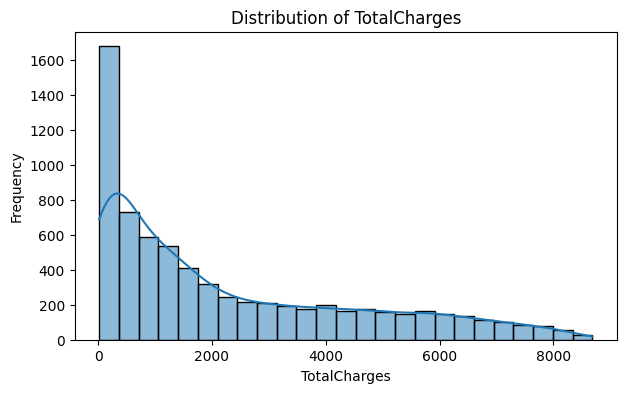

In [14]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

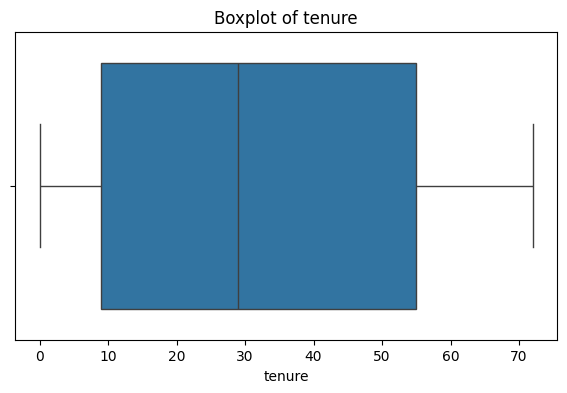

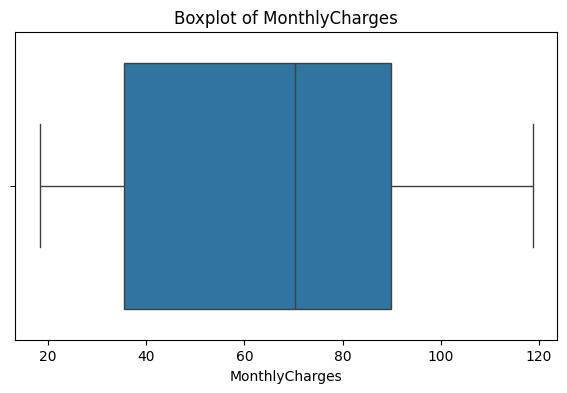

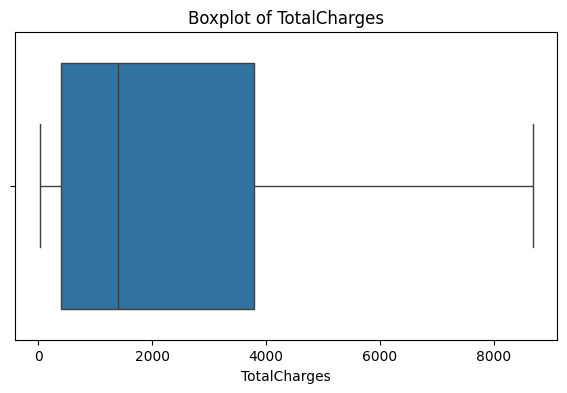

In [15]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

#splitting dataset

In [16]:

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


df = df.drop('customerID', axis=1)


X = df.drop('Churn', axis=1)

y = df['Churn'].map({'Yes': 1, 'No': 0})

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("Training data:")
print(y_train.value_counts())

print("\nTesting data:")
print(y_test.value_counts())

Training data shape: (5634, 19)
Testing data shape: (1409, 19)
Training target shape: (5634,)
Testing target shape: (1409,)
Training data:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing data:
Churn
0    1035
1     374
Name: count, dtype: int64


##Handling null value

In [19]:
print(X_train.isnull().sum())
print(X_test.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        8
dtype: int64
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        3
dtype: int64


In [20]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

num_imputer = SimpleImputer(strategy='median')

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

In [21]:
print("Training missing values:")
print(X_train.isnull().sum().sum())

print("Testing missing values:")
print(X_test.isnull().sum().sum())

Training missing values:
0
Testing missing values:
0


In [22]:
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test[num_cols] = scaler.transform(X_test[num_cols])

#categorical cols handling

In [23]:
# Binary mapping
binary_mapping = {
    'gender': {'Female': 0, 'Male': 1},
    'Partner': {'No': 0, 'Yes': 1},
    'Dependents': {'No': 0, 'Yes': 1},
    'PhoneService': {'No': 0, 'Yes': 1},
    'PaperlessBilling': {'No': 0, 'Yes': 1}
}

for col, mapping in binary_mapping.items():
    X_train[col] = X_train[col].map(mapping)
    X_test[col] = X_test[col].map(mapping)

In [24]:
contract_mapping = {
    'Month-to-month': 0,
    'One year': 1,
    'Two year': 2
}

X_train['Contract'] = X_train['Contract'].map(contract_mapping)
X_test['Contract'] = X_test['Contract'].map(contract_mapping)

In [25]:
# Select categorical columns except already mapped columns
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print(categorical_cols)

['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaymentMethod']


In [26]:
# Initialize OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit on training data and transform both datasets
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

# Convert encoded data into DataFrames
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

In [27]:
# Drop original categorical columns
X_train = X_train.drop(columns=categorical_cols)
X_test = X_test.drop(columns=categorical_cols)

# Combine numerical and encoded columns
X_train = pd.concat([X_train, X_train_encoded], axis=1)
X_test = pd.concat([X_test, X_test_encoded], axis=1)

In [28]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

display(X_train.head())

Training data shape: (5634, 38)
Testing data shape: (1409, 38)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,...,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,-0.441773,0,0,0.102371,0,0,0,-0.521976,-0.263290,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3151,1,-0.441773,1,1,-0.711743,1,0,0,0.337478,-0.504815,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,1,-0.441773,1,1,-0.793155,0,2,0,-0.809013,-0.751214,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3867,0,-0.441773,1,0,-0.263980,1,2,1,0.284384,-0.173700,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,1,-0.441773,1,1,-1.281624,1,0,0,-0.676279,-0.990851,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


#label encoding


In [29]:
# Target variable
y = df['Churn'].map({'Yes': 1, 'No': 0})

In [30]:
print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


#Class Imbalance

In [31]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [32]:
smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(X_train, y_train)

In [33]:
print("After SMOTE:")
print(y_train.value_counts())

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


#correlation

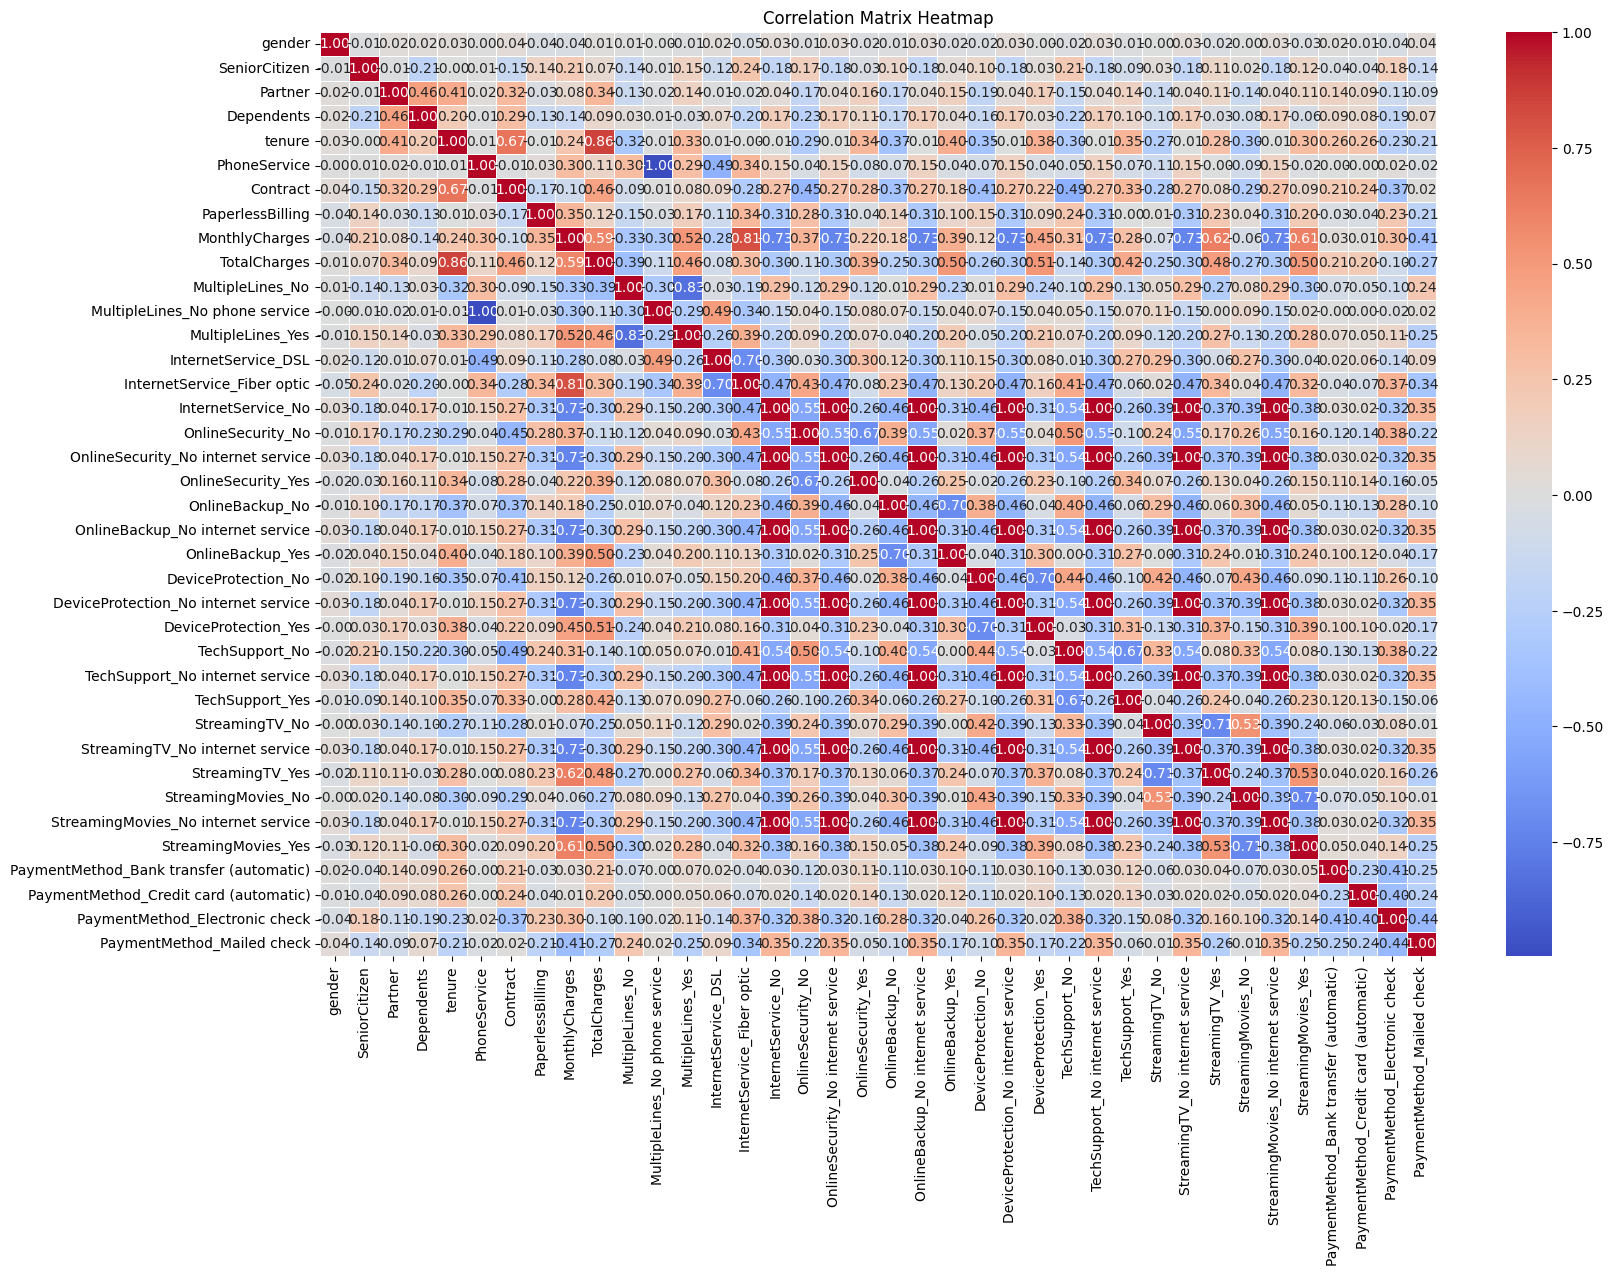

In [34]:
# Calculate the correlation matrix for the preprocessed training features
correlation_matrix = X_train.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix Heatmap")
plt.show()

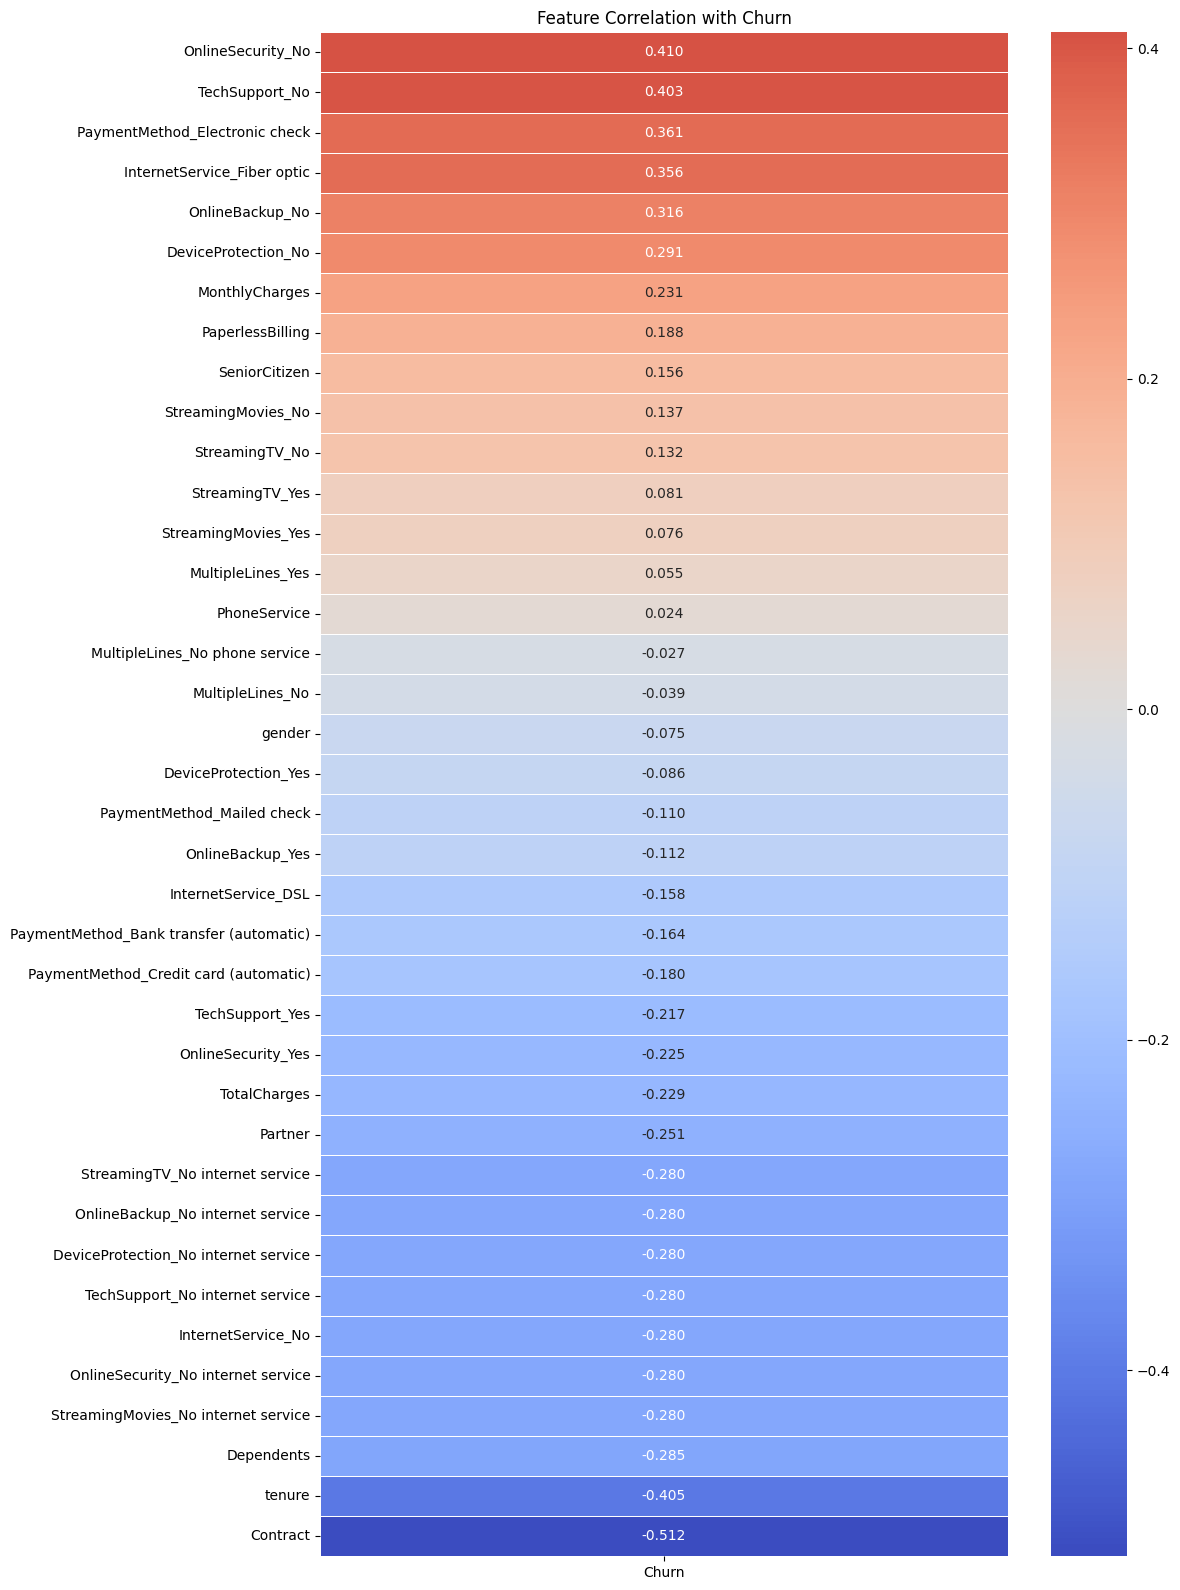

In [35]:
# Calculate correlation of each feature with target variable (using correct variable names)
corr = X_train.corrwith(
    pd.Series(y_train, index=X_train.index)
).sort_values(ascending=False).to_frame("Churn")

# Plot correlation heatmap
plt.figure(figsize=(12, 16))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)

plt.title("Feature Correlation with Churn")
plt.tight_layout()
plt.show()

In [36]:
features_selected = [
    'PaymentMethod_Electronic check',
    'DeviceProtection_No',
    'PaperlessBilling'
]
X_train_selected = X_train[features_selected]
X_test_selected = X_test[features_selected]

In [37]:
print(X_train_selected.head())
print("Training shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)

   PaymentMethod_Electronic check  DeviceProtection_No  PaperlessBilling
0                             1.0                  0.0                 0
1                             0.0                  1.0                 0
2                             0.0                  1.0                 0
3                             0.0                  0.0                 1
4                             1.0                  1.0                 0
Training shape: (8278, 3)
Testing shape: (1409, 3)


#KNN and Logistic Regression

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

#Logistic model Evaluavation

In [39]:
log_reg = LogisticRegression()

log_reg.fit(X_train_selected, y_train)

log_pred = log_reg.predict(X_test_selected)

In [40]:
log_train_pred = log_reg.predict(X_train_selected)

log_test_pred = log_reg.predict(X_test_selected)

In [41]:
log_train_acc = accuracy_score(y_train, log_train_pred)
log_test_acc = accuracy_score(y_test, log_test_pred)

print(f"Logistic Regression Train Accuracy: {log_train_acc:.4f}")
print(f"Logistic Regression Test Accuracy: {log_test_acc:.4f}")

Logistic Regression Train Accuracy: 0.6759
Logistic Regression Test Accuracy: 0.6402


In [42]:
log_cm = confusion_matrix(y_test, log_test_pred)

print("Confusion Matrix :",)
print(log_cm)

Confusion Matrix :
[[627 408]
 [ 99 275]]


In [43]:
print("=== Logistic Regression Evaluation ===")
print(classification_report(y_test, log_test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, log_test_pred))


=== Logistic Regression Evaluation ===
              precision    recall  f1-score   support

           0       0.86      0.61      0.71      1035
           1       0.40      0.74      0.52       374

    accuracy                           0.64      1409
   macro avg       0.63      0.67      0.62      1409
weighted avg       0.74      0.64      0.66      1409

Confusion Matrix:
 [[627 408]
 [ 99 275]]


In [44]:
y_prob = log_reg.predict_proba(X_test_selected)[:, 1]

print(y_prob[:10])

[0.29979343 0.52000135 0.29979343 0.50116249 0.29979343 0.52000135
 0.52000135 0.29979343 0.21446874 0.79945545]


In [45]:
thresholds = [0.3, 0.5, 0.7]

for t in thresholds:

    y_pred_threshold = (y_prob >= t).astype(int)

    print("\nThreshold:", t)

    print("Accuracy:", accuracy_score(y_test, y_pred_threshold))

    print("Precision:", precision_score(y_test, y_pred_threshold))

    print("Recall:", recall_score(y_test, y_pred_threshold))

    print("F1-score:", f1_score(y_test, y_pred_threshold))


Threshold: 0.3
Accuracy: 0.6061036195883606
Precision: 0.3878562577447336
Recall: 0.8368983957219251
F1-score: 0.5300592718035563

Threshold: 0.5
Accuracy: 0.6401703335699077
Precision: 0.40263543191800877
Recall: 0.7352941176470589
F1-score: 0.5203405865657521

Threshold: 0.7
Accuracy: 0.7288857345635202
Precision: 0.4862068965517241
Recall: 0.3770053475935829
F1-score: 0.4246987951807229


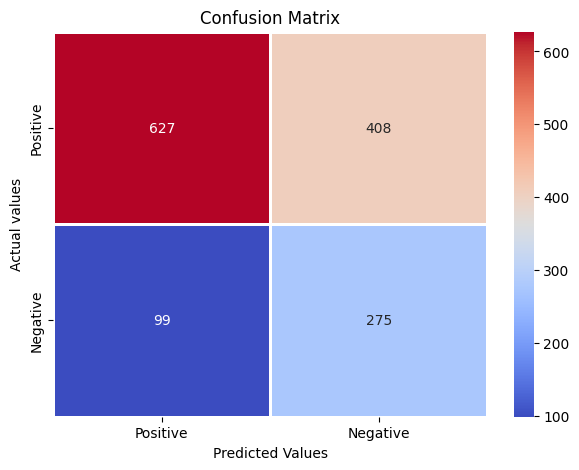

In [46]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    log_cm,
    annot=True,
    fmt='d',
    cmap="coolwarm",
    linewidths=1,
    xticklabels=['Positive', 'Negative'],
    yticklabels=['Positive', 'Negative']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual values')

plt.show()

#KNN Model Evaluvation

In [47]:
from sklearn.model_selection import train_test_split

# Split training data to create a validation set for hyperparameter tuning
X_train_knn, X_val, y_train_knn, y_val = train_test_split(
    X_train_selected, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

k_values = [1, 3, 5, 7, 9, 11]
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)
    y_val_pred = knn.predict(X_val)
    score = f1_score(y_val, y_val_pred)
    scores.append(score)
    print("K =", k, "F1-score =", score)

best_k = k_values[np.argmax(scores)]
print("Best K:", best_k)

K = 1 F1-score = 0.6934389140271493
K = 3 F1-score = 0.6466361854996734
K = 5 F1-score = 0.606015037593985
K = 7 F1-score = 0.657283603096411
K = 9 F1-score = 0.6544428772919605
K = 11 F1-score = 0.6553911205073996
Best K: 1


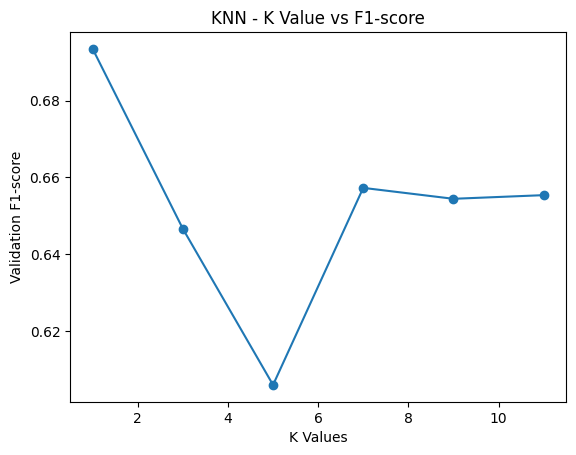

In [48]:
plt.plot(k_values, scores, marker='o')

plt.xlabel("K Values")
plt.ylabel("Validation F1-score")
plt.title("KNN - K Value vs F1-score")

plt.show()

In [49]:
knn = KNeighborsClassifier(n_neighbors=best_k)

knn.fit(X_train_selected, y_train)

knn_pred = knn.predict(X_test_selected)

In [50]:
knn_train_pred = knn.predict(X_train_selected)
knn_test_pred = knn.predict(X_test_selected)

In [51]:
knn_train_acc = accuracy_score(y_train, knn_train_pred )
knn_test_acc = accuracy_score(y_test, knn_test_pred)

print(f"KNN Train Accuracy: {knn_train_acc:.4f}")
print(f"KNN Test Accuracy: {knn_test_acc:.4f}")

KNN Train Accuracy: 0.6563
KNN Test Accuracy: 0.7005


In [52]:
knn_cm = confusion_matrix(y_test, knn_test_pred)

print("Confusion Matrix :")
print(knn_cm)

Confusion Matrix :
[[835 200]
 [222 152]]


In [53]:
print("=== KNN Evaluation ===")
print(classification_report(y_test, knn_test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, knn_test_pred))


=== KNN Evaluation ===
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      1035
           1       0.43      0.41      0.42       374

    accuracy                           0.70      1409
   macro avg       0.61      0.61      0.61      1409
weighted avg       0.69      0.70      0.70      1409

Confusion Matrix:
 [[835 200]
 [222 152]]


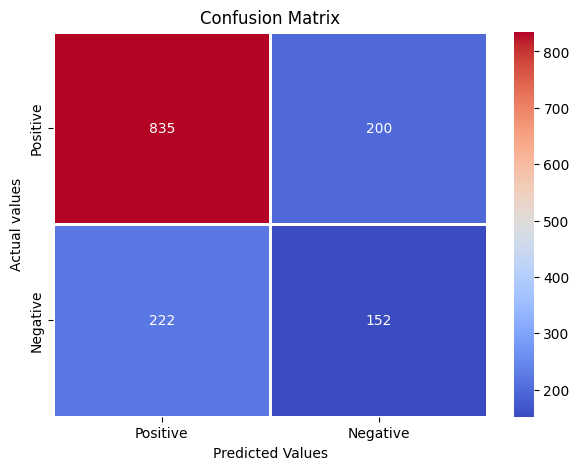

In [54]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap="coolwarm",
    linewidths=1,
    xticklabels=['Positive', 'Negative'],
    yticklabels=['Positive', 'Negative']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual values')

plt.show()

#COMPARISON OF KNN AND LOGISTIC REGRESSION

In [55]:
comparison = pd.DataFrame({

    'Model': ['KNN', 'Logistic Regression'],

    'Accuracy': [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, log_pred)
    ],

    'Precision': [
        precision_score(y_test, knn_pred),
        precision_score(y_test, log_pred)
    ],

    'Recall': [
        recall_score(y_test, knn_pred),
        recall_score(y_test, log_pred)
    ],

    'F1-score': [
        f1_score(y_test, knn_pred),
        f1_score(y_test, log_pred)
    ]

})

display(comparison)

,Model,Accuracy,Precision,Recall,F1-score
0,KNN,0.700497,0.431818,0.406417,0.418733
1,Logistic Regression,0.640170,0.402635,0.735294,0.520341


In [56]:
if f1_score(y_test, knn_pred) > f1_score(y_test, log_pred):

    print("KNN is the better model.")

else:

    print("Logistic Regression is the better model.")

Logistic Regression is the better model.


     1. False Positive (FP)

A false positive happens when the model predicts that a customer will leave the company, but the customer continues to use its services.
As a result, the company may offer unnecessary discounts or special benefits to customers who were not planning to leave, leading to additional marketing costs.
    
     2. False Negative (FN)

A false negative occurs when the model predicts that a customer will remain with the company, but the customer actually stops using its services.
This can cause the company to lose valuable customers and revenue because it fails to recognize customers who are likely to leave.
    
     3. Conclusion
     
Both false positives and false negatives affect the performance of customer churn prediction. False negatives can lead to unexpected customer loss, while false positives may result in unnecessary spending on retention activities. Therefore, reducing both types of errors helps companies make better decisions and manage their resources effectively